# 02 – DistilBERT finomhangolás

`distilbert-base-uncased`, max. 256 token, 2 epoch, ugyanazon a felbontáson és metrikákkal, mint a 01. Ha van mentett modell, betölti (`RETRAIN = False`).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import set_seed

from common import FIG_DIR, METRICS_DIR, RESULTS_DIR, SEED, labels_for, load_split, results_table
from train_utils import RunConfig, count_tokens, describe_device, evaluate_5to3, load_tokenizer, run_task

CFG = RunConfig(name="distilbert", max_len=256, epochs=2, per_device_batches=(16, 8))
set_seed(SEED)
describe_device()

torch 2.15.0+cu132 | NVIDIA GeForce GTX 1660 | free GPU memory: 5.0 / 6.0 GB


## 1. Adat

In [2]:
split = load_split()
test_df = split["test"]
{name: len(df) for name, df in split.items()}

{'train': 14400, 'val': 1600, 'test': 4000}

## 2. Szöveghossz tokenekben

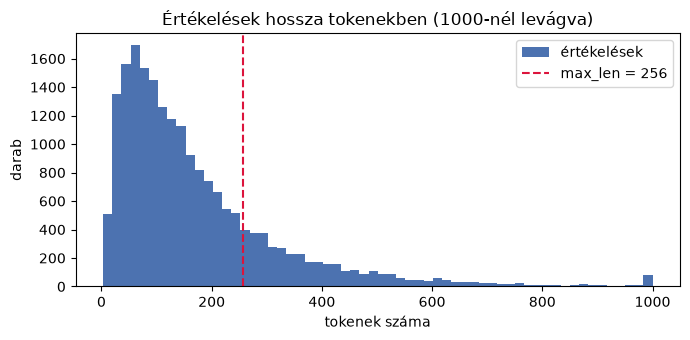

{'max_len': 256,
 'tokens_median': 128.0,
 'tokens_mean': 173.8806,
 'tokens_p90': 366.1000000000022,
 'share_truncated_at_max_len': 0.2012,
 'share_over_512': 0.04165}

In [3]:
tokenizer = load_tokenizer(CFG)
n_tokens = pd.Series(count_tokens(tokenizer, pd.concat(split.values())["text"]))

token_stats = {
    "max_len": CFG.max_len,
    "tokens_median": float(n_tokens.median()),
    "tokens_mean": float(n_tokens.mean()),
    "tokens_p90": float(n_tokens.quantile(.9)),
    "share_truncated_at_max_len": float((n_tokens > CFG.max_len).mean()),
    "share_over_512": float((n_tokens > 512).mean()),
}
(RESULTS_DIR / "token_stats.json").write_text(json.dumps(token_stats, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(7, 3.5))
n_tokens.clip(upper=1000).plot.hist(bins=60, ax=ax, color="#4C72B0", label="értékelések")
ax.axvline(CFG.max_len, color="crimson", ls="--", label=f"max_len = {CFG.max_len}")
ax.set(title="Értékelések hossza tokenekben (1000-nél levágva)", xlabel="tokenek száma", ylabel="darab")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_token_length.png", dpi=200, bbox_inches="tight")
plt.show()
token_stats

## 3. Tanítás

fp32, effektív batch 16, tanulási ráta 2e-5; a legjobb epochot a validációs macro-F1 alapján tartjuk meg.

### 5 osztály

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Mentett modell betöltése: E:\Tanulmányok\Óbudai Egyetem\MSc - Data Science\3. szemeszter\Mesterséges intelligencia alkalmazási területei\Féléves feladat\yelp-sentiment-distilbert\models\distilbert_5class


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

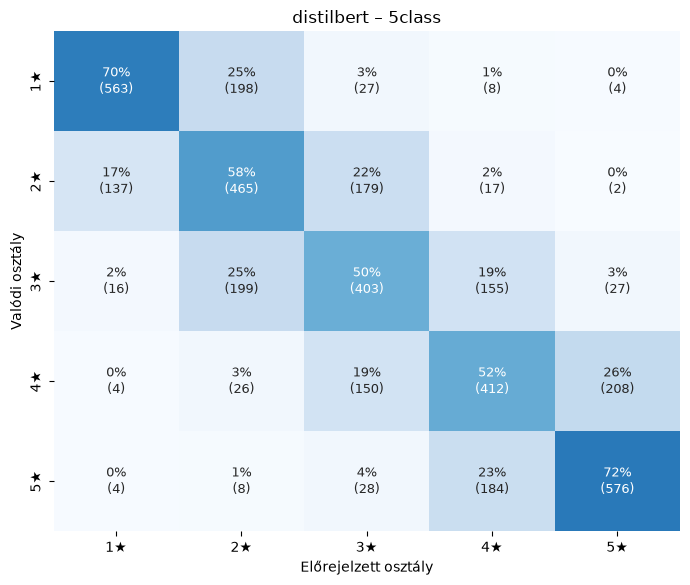

distilbert / 5class: accuracy=0.6048  macro-F1=0.6061


In [4]:
proba5, info5 = run_task(CFG, "5class", split, tokenizer)

### 3 osztály

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Mentett modell betöltése: E:\Tanulmányok\Óbudai Egyetem\MSc - Data Science\3. szemeszter\Mesterséges intelligencia alkalmazási területei\Féléves feladat\yelp-sentiment-distilbert\models\distilbert_3class


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

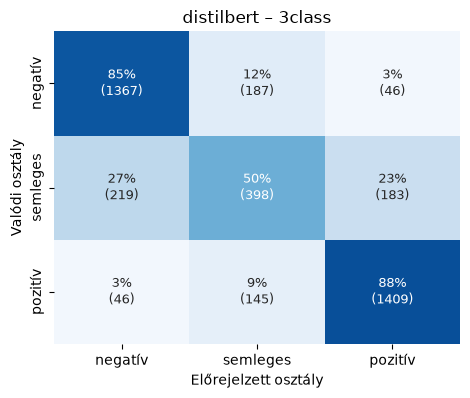

distilbert / 3class: accuracy=0.7935  macro-F1=0.7455


In [5]:
proba3, info3 = run_task(CFG, "3class", split, tokenizer)

### 5 osztályos előrejelzés összevonása 3 osztályra

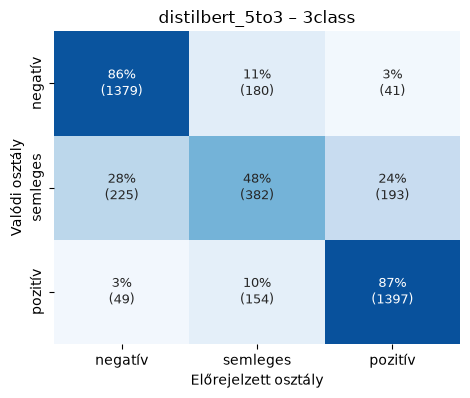

distilbert_5to3 / 3class: accuracy=0.7895  macro-F1=0.7388


In [6]:
evaluate_5to3(CFG.name, proba5, test_df)

## 4. Tanulási görbék

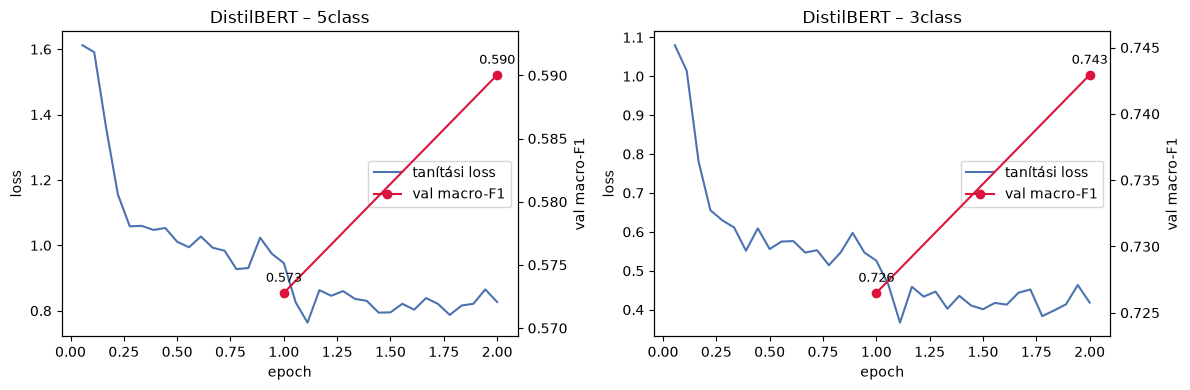

,5class,3class
tanítási idő (perc),9.0,9.0
legjobb val macro-F1,0.59,0.7429
batch (eszközönként x akkumuláció),16 x 1,16 x 1


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (task, info) in zip(axes, [("5class", info5), ("3class", info3)]):
    hist = pd.DataFrame(info["log_history"])
    tr = hist.dropna(subset=["loss"]) if "loss" in hist else pd.DataFrame()
    ev = hist.dropna(subset=["eval_macro_f1"]) if "eval_macro_f1" in hist else pd.DataFrame()
    if not tr.empty:
        ax.plot(tr["epoch"], tr["loss"] / info["gradient_accumulation_steps"], color="#4C72B0", label="tanítási loss")
    ax.set(title=f"DistilBERT – {task}", xlabel="epoch", ylabel="loss")
    ax2 = ax.twinx()
    if not ev.empty:
        ax2.plot(ev["epoch"], ev["eval_macro_f1"], "o-", color="crimson", label="val macro-F1")
        for _, r in ev.iterrows():
            ax2.annotate(f"{r['eval_macro_f1']:.3f}", (r["epoch"], r["eval_macro_f1"]),
                         textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax2.set_ylabel("val macro-F1")
    ax2.margins(y=0.2)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "distilbert_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({task: {"tanítási idő (perc)": round(i["train_seconds"] / 60, 1),
                     "legjobb val macro-F1": round(i["best_val_macro_f1"], 4),
                     "batch (eszközönként x akkumuláció)": f"{i['per_device_batch_size']} x {i['gradient_accumulation_steps']}"}
              for task, i in [("5class", info5), ("3class", info3)]})

## 5. Összevetés a baseline-nal

In [8]:
summary = results_table()
summary.to_csv(RESULTS_DIR / "summary.csv", index=False, encoding="utf-8")
display(summary.style.format({c: "{:.3f}" for c in summary.columns if c not in ("model", "task")}))

s = summary.set_index(["task", "model"])
delta = pd.DataFrame({task: (s.loc[(task, "distilbert")] - s.loc[(task, "tfidf_logreg")])[["accuracy", "macro_f1"]] * 100
                      for task in ("5class", "3class")}).T.round(1)
delta.columns = ["Δ accuracy (%-pont)", "Δ macro-F1 (%-pont)"]
delta

,model,task,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,majority,3class,0.400,0.133,0.333,0.190,0.229
1,tfidf_logreg_5to3,3class,0.767,0.719,0.697,0.698,0.752
2,tfidf_logreg,3class,0.772,0.721,0.708,0.710,0.761
3,distilbert_5to3,3class,0.789,0.741,0.737,0.739,0.786
4,distilbert,3class,0.793,0.748,0.744,0.745,0.791
5,distilbert_512_3ep_5to3,3class,0.800,0.752,0.749,0.750,0.797
6,distilbert_512_3ep,3class,0.802,0.757,0.754,0.755,0.800
7,majority,5class,0.200,0.040,0.200,0.067,0.067
8,tfidf_logreg,5class,0.561,0.558,0.561,0.559,0.559
9,distilbert,5class,0.605,0.609,0.605,0.606,0.606


,Δ accuracy (%-pont),Δ macro-F1 (%-pont)
5class,4.4,4.7
3class,2.1,3.6


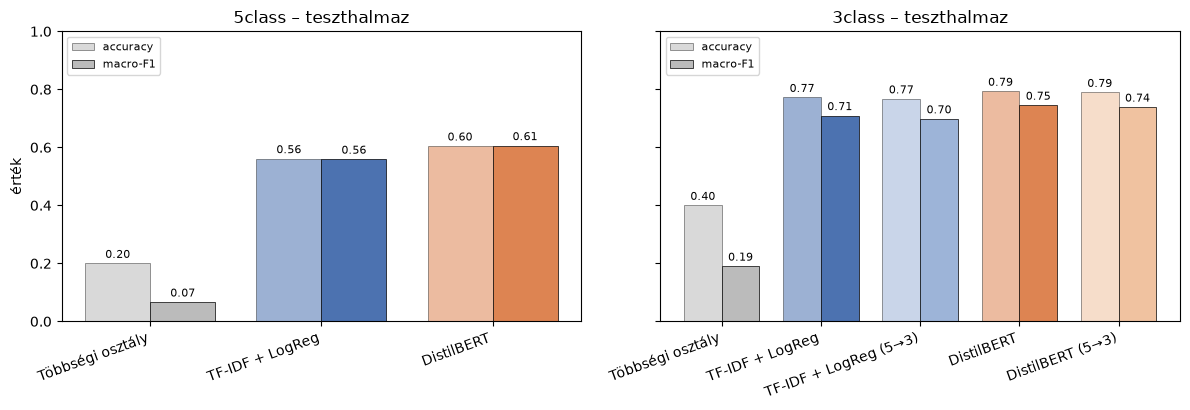

In [9]:
MODEL_NAMES = {"majority": "Többségi osztály", "tfidf_logreg": "TF-IDF + LogReg",
               "tfidf_logreg_5to3": "TF-IDF + LogReg (5→3)", "distilbert": "DistilBERT",
               "distilbert_5to3": "DistilBERT (5→3)"}
COLORS = {"majority": "#BBBBBB", "tfidf_logreg": "#4C72B0", "tfidf_logreg_5to3": "#9DB4D8",
          "distilbert": "#DD8452", "distilbert_5to3": "#F0C2A0"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, task in zip(axes, ("5class", "3class")):
    sub = summary[summary["task"] == task].set_index("model")
    order = [m for m in MODEL_NAMES if m in sub.index]
    x = np.arange(len(order))
    for j, metric in enumerate(("accuracy", "macro_f1")):
        vals = sub.loc[order, metric].to_numpy()
        bars = ax.bar(x + (j - 0.5) * 0.38, vals, width=0.38,
                      color=[COLORS[m] for m in order], alpha=1 if j == 1 else 0.55,
                      edgecolor="black", linewidth=0.5, label="macro-F1" if j == 1 else "accuracy")
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(x, [MODEL_NAMES[m] for m in order], rotation=20, ha="right")
    ax.set(title=f"{task} – teszthalmaz", ylim=(0, 1))
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("érték")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### Osztályonkénti F1

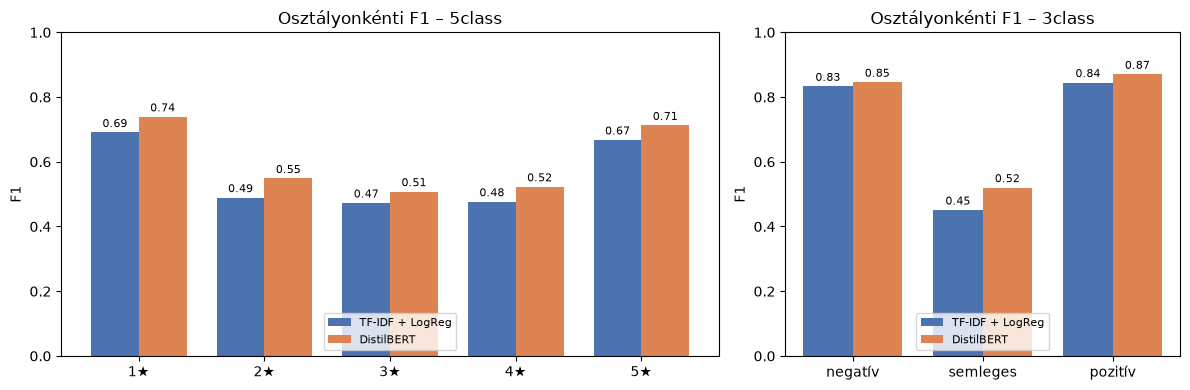

model            tfidf_logreg  distilbert      Δ
task   class                                    
5class 1★               0.690       0.739  0.048
       2★               0.489       0.548  0.059
       3★               0.473       0.508  0.035
       4★               0.477       0.523  0.046
       5★               0.667       0.712  0.045
3class negatív          0.833       0.846  0.013
       semleges         0.451       0.520  0.069
       pozitív          0.845       0.870  0.025

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [5, 3]})
per_class_rows = []
for ax, task in zip(axes, ("5class", "3class")):
    labels = labels_for(task)
    x = np.arange(len(labels))
    for j, model in enumerate(("tfidf_logreg", "distilbert")):
        m = json.loads((METRICS_DIR / f"{model}_{task}.json").read_text(encoding="utf-8"))
        f1s = [m["per_class"][lab]["f1"] for lab in labels]
        per_class_rows += [{"task": task, "model": model, "class": lab, "f1": f} for lab, f in zip(labels, f1s)]
        bars = ax.bar(x + (j - 0.5) * 0.38, f1s, width=0.38, color=COLORS[model], label=MODEL_NAMES[model])
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(x, labels)
    ax.set(title=f"Osztályonkénti F1 – {task}", ylim=(0, 1), ylabel="F1")
    ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()

per_class = pd.DataFrame(per_class_rows).pivot_table(index=["task", "class"], columns="model", values="f1", sort=False)
per_class["Δ"] = per_class["distilbert"] - per_class["tfidf_logreg"]
per_class.round(3)